<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 12: CNN Architecture and Hyperparameter Comparison

**Course Outcome**: CO2 – Neural Networks and CNNs  
**Problem Statement**: The recycling plant’s CNN must run on a low-cost edge device. The engineer must balance accuracy against model size and training time. The same waste or CIFAR-10 dataset from Experiment 11. The objective is to compare CNN architectures and hyperparameters systematically. Use TensorFlow, Keras, NumPy, Matplotlib. Vary the number of convolution layers (2, 3, 4). Vary filter size (3×3, 5×5) and filter count.


1. Vary the number of convolution layers (2, 3, 4)

In [9]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

(x, y), (xt, yt) = tf.keras.datasets.mnist.load_data()
x = x[:2000].reshape(-1,28,28,1)/255.0
y = y[:2000]
xt = xt[:500].reshape(-1,28,28,1)/255.0
yt = yt[:500]

def cnn(n=2, k=3, f=16, pool='max', bn=False, lr=0.001):
    m = tf.keras.Sequential([tf.keras.Input(shape=(28,28,1))])
    for i in range(n):
        m.add(tf.keras.layers.Conv2D(f,k,padding='same',activation='relu'))
        if bn:
            m.add(tf.keras.layers.BatchNormalization())
        if i < 2:
            m.add(tf.keras.layers.MaxPooling2D() if pool=='max'
                  else tf.keras.layers.AveragePooling2D(pool_size=(2,2)))
    m.add(tf.keras.layers.Flatten())
    m.add(tf.keras.layers.Dense(10,activation='softmax'))
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
    return m

def test(name, **kwargs):
    bs = kwargs.pop('batch_size',32)
    m = cnn(**kwargs)
    start = time.time()
    m.fit(x,y,epochs=2,batch_size=bs,verbose=0)
    sec = round(time.time()-start,2)
    acc = round(m.evaluate(xt,yt,verbose=0)[1]*100,2)
    result = [name,acc,m.count_params(),sec]
    print(result)
    return result


['2 Layers', 87.6, 10330, 4.72]
['3 Layers', 84.6, 12650, 3.56]
['4 Layers', 87.4, 14970, 5.19]


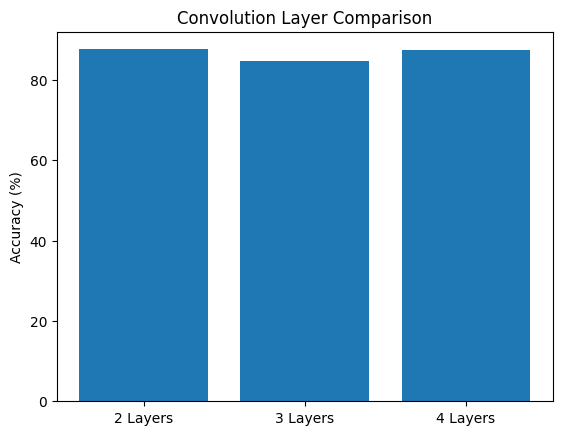

In [3]:

r1 = []
for n in [2,3,4]:
    r1.append(test(f'{n} Layers',n=n))

plt.bar([r[0] for r in r1],[r[1] for r in r1])
plt.ylabel('Accuracy (%)')
plt.title('Convolution Layer Comparison')
plt.show()


2. Vary filter size (3×3, 5×5) and filter count

['3x3, 16 filters', 84.4, 10330, 3.97]
['3x3, 32 filters', 89.4, 25258, 8.62]
['5x5, 16 filters', 85.8, 14682, 5.46]
['5x5, 32 filters', 90.0, 42154, 14.4]


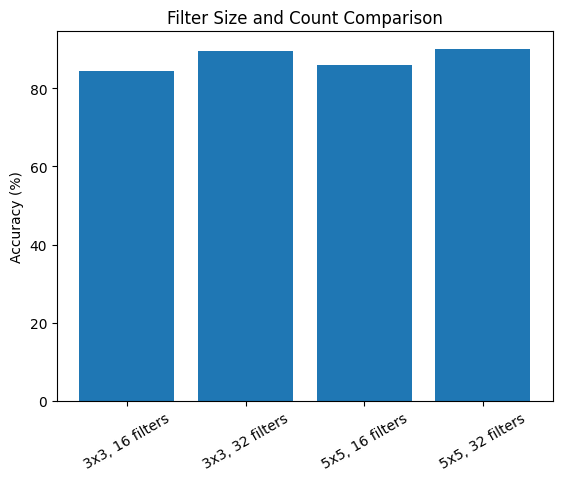

In [4]:

r2 = []
for k in [3,5]:
    for f in [16,32]:
        r2.append(test(f'{k}x{k}, {f} filters',k=k,f=f))

plt.bar([r[0] for r in r2],[r[1] for r in r2])
plt.xticks(rotation=30)
plt.ylabel('Accuracy (%)')
plt.title('Filter Size and Count Comparison')
plt.show()


3. Compare max pooling and average pooling, with and without batch normalization

['max, BN=False', 85.8, 10330, 4.15]
['max, BN=True', 59.0, 10458, 5.65]
['avg, BN=False', 81.6, 10330, 3.12]
['avg, BN=True', 44.8, 10458, 6.02]


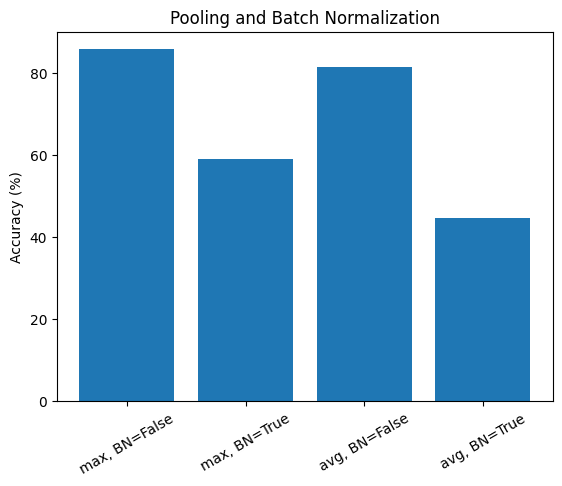

In [10]:

r3 = []
for p in ['max','avg']:
    for bn in [False,True]:
        r3.append(test(f'{p}, BN={bn}',pool=p,bn=bn))

plt.bar([r[0] for r in r3],[r[1] for r in r3])
plt.xticks(rotation=30)
plt.ylabel('Accuracy (%)')
plt.title('Pooling and Batch Normalization')
plt.show()


4. Vary learning rate and batch size

['LR=0.001, BS=32', 88.0, 10330, 3.04]
['LR=0.001, BS=64', 75.8, 10330, 4.09]
['LR=0.0001, BS=32', 39.4, 10330, 3.38]
['LR=0.0001, BS=64', 14.8, 10330, 2.84]


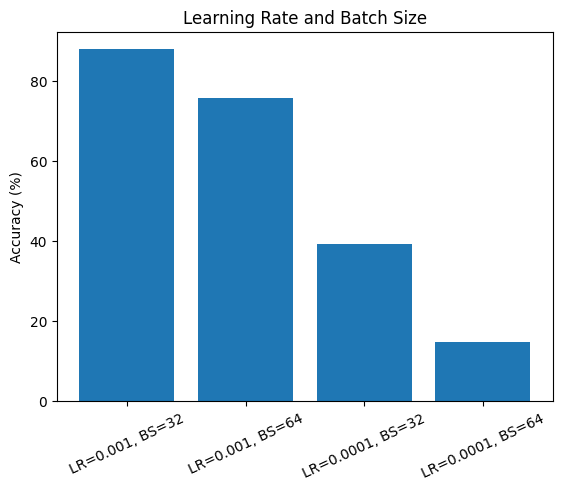

In [7]:

r4 = []
for lr in [0.001,0.0001]:
    for bs in [32,64]:
        r4.append(test(f'LR={lr}, BS={bs}',lr=lr,batch_size=bs))

plt.bar(range(len(r4)),[r[1] for r in r4])
plt.xticks(range(len(r4)),[r[0] for r in r4],rotation=25)
plt.ylabel('Accuracy (%)')
plt.title('Learning Rate and Batch Size')
plt.show()


5. Tabulate accuracy, parameter count and training time

In [8]:

import pandas as pd

results = r1 + r2 + r3 + r4

df = pd.DataFrame(results,columns=[
    'Configuration','Accuracy (%)','Parameters','Time (sec)'
])

print(df.to_string(index=False))

print("\nBest Configuration:")
print(df.loc[df['Accuracy (%)'].idxmax()].to_string())


   Configuration  Accuracy (%)  Parameters  Time (sec)
        2 Layers          87.6       10330        4.72
        3 Layers          84.6       12650        3.56
        4 Layers          87.4       14970        5.19
 3x3, 16 filters          84.4       10330        3.97
 3x3, 32 filters          89.4       25258        8.62
 5x5, 16 filters          85.8       14682        5.46
 5x5, 32 filters          90.0       42154       14.40
   max, BN=False          84.8       10330        5.18
    max, BN=True          36.0       10458        4.44
 LR=0.001, BS=32          88.0       10330        3.04
 LR=0.001, BS=64          75.8       10330        4.09
LR=0.0001, BS=32          39.4       10330        3.38
LR=0.0001, BS=64          14.8       10330        2.84

Best Configuration:
Configuration    5x5, 32 filters
Accuracy (%)                90.0
Parameters                 42154
Time (sec)                  14.4
